# Demonstração — remoção de ruído com a rede R-CED

Este notebook faz parte da pasta `simple/`, a versão simplificada e autocontida
do pipeline deste repositório (as contas são as mesmas do pipeline principal,
então os resultados também são os mesmos).

O que ele faz:

1. carrega o modelo R-CED já treinado (`best.keras`);
2. escolhe um arquivo ruidoso do conjunto de validação;
3. remove o ruído com a rede;
4. mostra as formas de onda, os espectrogramas e o áudio para ouvir,
   junto com o SDR antes e depois.

Rodar dentro do container `tensorflow-2026`, sem o Keras legado:

```
env -u TF_USE_LEGACY_KERAS jupyter notebook
```

In [1]:
import json
import os

import numpy as np
import librosa
import soundfile as sf
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# garante que o notebook rode a partir da raiz do repositorio
if os.path.basename(os.getcwd()) == "simple":
    os.chdir("..")


# parametros do projeto (os mesmos dos scripts da pasta simple/)

TAXA_AMOSTRAGEM = 16000

TAMANHO_FFT = 512
PASSO_STFT = 128

AMOSTRAS_SEGMENTO = 32000      # 2 segundos
PASSO_SEGMENTO = 16000         # 50% de sobreposicao

# constante global de normalizacao, calculada na etapa 1 sobre o treino
MAX_MAG = 17.226323333741856

CAMINHO_MODELO = "models/runs/park_rced_park_data/best.keras"

# arquivo da validacao usado na demonstracao (SNR de entrada: 5 dB)
ARQUIVO_RUIDOSO = "dataset/NoisySpeech_training/noisy3388_SNRdb_5.0_clnsp3388.wav"
ARQUIVO_LIMPO = "dataset/CleanSpeech_training/clnsp3388.wav"

2026-08-09 23:18:30.593589: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## 1. Carregar o modelo treinado

In [2]:
# GPU com precisao mista, como no treino
gpus = tf.config.experimental.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
tf.keras.mixed_precision.set_global_policy("mixed_float16")

modelo = tf.keras.models.load_model(CAMINHO_MODELO, compile=False)

print(f"Modelo carregado: {CAMINHO_MODELO}")
print(f"Parametros: {modelo.count_params()}")

I0000 00:00:1786317512.902223   11383 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9554 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070, pci bus id: 0000:0e:00.0, compute capability: 8.9


Modelo carregado: models/runs/park_rced_park_data/best.keras
Parametros: 352361


## 2. Carregar o áudio de teste

O arquivo escolhido pertence ao conjunto de validação (locutores que a rede
nunca viu no treino). A versão limpa serve só como referência para medir a
qualidade — a rede recebe apenas o áudio ruidoso.

In [3]:
def carregar_audio(caminho):

    audio, sr = sf.read(caminho, dtype="float32")

    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    if sr != TAXA_AMOSTRAGEM:
        raise RuntimeError(f"{caminho}: taxa {sr}, esperado {TAXA_AMOSTRAGEM}")

    return audio


ruidoso = carregar_audio(ARQUIVO_RUIDOSO)
limpo = carregar_audio(ARQUIVO_LIMPO)

menor = min(len(limpo), len(ruidoso))
limpo = limpo[:menor]
ruidoso = ruidoso[:menor]

print(f"Duracao: {menor / TAXA_AMOSTRAGEM:.1f} s ({menor} amostras)")

Duracao: 10.0 s (160000 amostras)


## 3. Funções de processamento

São as mesmas contas do script `3_avaliar_modelo.py`:

- o áudio é cortado em segmentos de 2 s com 50% de sobreposição;
- cada segmento vira uma STFT, e a magnitude (em `log1p`, normalizada)
  passa pela rede;
- o áudio é reconstruído com a magnitude prevista e a **fase do sinal
  ruidoso**;
- os segmentos são juntados de volta com overlap-add (janela de Hann).

In [4]:
def calcular_stft(audio):

    return librosa.stft(
        audio,
        n_fft=TAMANHO_FFT,
        hop_length=PASSO_STFT,
        win_length=TAMANHO_FFT,
        window="hann",
        center=True,
    )


def calcular_istft(stft):

    return librosa.istft(
        stft,
        hop_length=PASSO_STFT,
        win_length=TAMANHO_FFT,
        window="hann",
        center=True,
    )


def cortar_em_segmentos(audio):

    segmentos = []
    inicio = 0
    while inicio + AMOSTRAS_SEGMENTO <= len(audio):
        pedaco = audio[inicio:inicio + AMOSTRAS_SEGMENTO]
        segmentos.append((inicio, pedaco))
        inicio = inicio + PASSO_SEGMENTO

    # ultimo pedaco alinhado com o fim, se sobrar trecho sem cobertura
    if len(audio) > AMOSTRAS_SEGMENTO:
        resto = len(audio) - AMOSTRAS_SEGMENTO
        if resto > PASSO_SEGMENTO and resto < AMOSTRAS_SEGMENTO:
            inicio_final = len(audio) - AMOSTRAS_SEGMENTO
            segmentos.append((inicio_final, audio[inicio_final:]))

    return segmentos


def juntar_segmentos(segmentos, tamanho_total):

    saida = np.zeros(tamanho_total)
    pesos = np.zeros(tamanho_total)
    janela = np.hanning(AMOSTRAS_SEGMENTO)

    for inicio, pedaco in segmentos:
        fim = min(inicio + AMOSTRAS_SEGMENTO, tamanho_total)
        n = fim - inicio
        saida[inicio:fim] = saida[inicio:fim] + pedaco[:n] * janela[:n]
        pesos[inicio:fim] = pesos[inicio:fim] + janela[:n]

    pesos = np.maximum(pesos, 1e-8)
    return saida / pesos


def remover_ruido(modelo, ruidoso):

    segmentos = cortar_em_segmentos(ruidoso)

    stfts = []
    entradas = []
    for inicio, pedaco in segmentos:
        stft = calcular_stft(pedaco)
        magnitude = np.abs(stft)
        entrada = np.log1p(magnitude / MAX_MAG).astype(np.float32)
        stfts.append(stft)
        entradas.append(entrada[..., np.newaxis])

    entradas = np.array(entradas)
    previsoes = modelo.predict(entradas, verbose=0)

    segmentos_limpos = []
    for i in range(len(segmentos)):

        log_magnitude = previsoes[i][..., 0].astype(np.float64)
        magnitude = np.expm1(log_magnitude)
        magnitude = np.maximum(magnitude, 0.0)
        magnitude = magnitude * MAX_MAG

        fase = np.angle(stfts[i])
        stft_estimada = magnitude * np.exp(1j * fase)

        audio_estimado = calcular_istft(stft_estimada)

        if len(audio_estimado) >= AMOSTRAS_SEGMENTO:
            audio_estimado = audio_estimado[:AMOSTRAS_SEGMENTO]
        else:
            faltam = AMOSTRAS_SEGMENTO - len(audio_estimado)
            audio_estimado = np.pad(audio_estimado, (0, faltam))

        segmentos_limpos.append((segmentos[i][0], audio_estimado))

    return juntar_segmentos(segmentos_limpos, len(ruidoso))


def calcular_sdr(referencia, estimado):

    referencia = referencia.flatten()
    estimado = estimado.flatten()

    menor = min(len(referencia), len(estimado))
    referencia = referencia[:menor]
    estimado = estimado[:menor]

    erro = referencia - estimado
    potencia_sinal = np.sum(referencia ** 2) + 1e-8
    potencia_erro = np.sum(erro ** 2) + 1e-8

    return 10 * np.log10(potencia_sinal / potencia_erro)

## 4. Remover o ruído e medir o SDR

In [5]:
estimado = remover_ruido(modelo, ruidoso)
estimado = estimado[:menor]

sdr_antes = calcular_sdr(limpo, ruidoso)
sdr_depois = calcular_sdr(limpo, estimado)

print(f"SDR antes  (ruidoso):  {sdr_antes:6.2f} dB")
print(f"SDR depois (limpado):  {sdr_depois:6.2f} dB")
print(f"Melhora:               {sdr_depois - sdr_antes:+6.2f} dB")

2026-08-09 23:18:34.752353: I external/local_xla/xla/service/service.cc:163] XLA service 0x787498076e70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-08-09 23:18:34.752378: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4070, Compute Capability 8.9
2026-08-09 23:18:34.763660: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-08-09 23:18:34.874182: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90701


2026-08-09 23:18:44.268665: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng22{k2=3,k13=0,k14=2,k18=1,k23=0} for conv (f16[9,257,251,16]{3,2,1,0}, u8[0]{0}) custom-call(f16[9,257,251,16]{3,2,1,0}, f16[16,9,9,16]{3,2,1,0}), window={size=9x9 pad=4_4x4_4}, dim_labels=b01f_o01i->b01f, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-08-09 23:18:44.272961: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 3.603760439s
Trying algorithm eng22{k2=3,k13=0,k14=2,k18=1,k23=0} for conv (f16[9,257,251,16]{3,2,1,0}, u8[0]{0}) custom-call(f16[9,257,251,16]{3,2,1,0}, f16[16,9,9,16]{3,2,1,0}), window={size=9x9 pad=4_4x4_4}, dim_labels=b01f_o01i->b01f, custom_call_target="__cudnn$c

SDR antes  (ruidoso):    5.00 dB
SDR depois (limpado):   12.59 dB
Melhora:                +7.59 dB


I0000 00:00:1786317526.003127   11502 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


## 5. Formas de onda

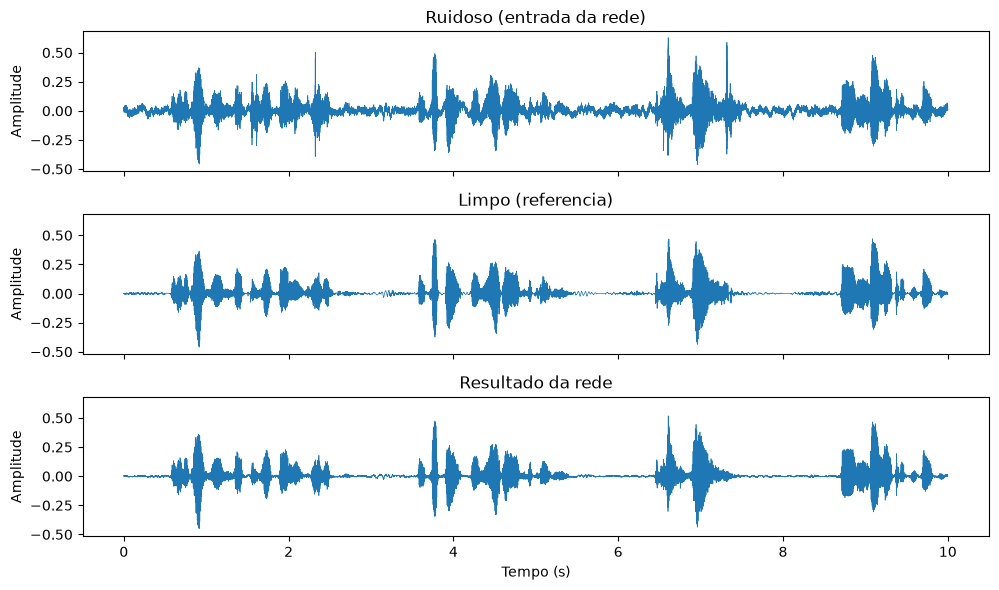

In [6]:
tempo = np.arange(menor) / TAXA_AMOSTRAGEM

figura, eixos = plt.subplots(3, 1, figsize=(10, 6), sharex=True, sharey=True)

eixos[0].plot(tempo, ruidoso, linewidth=0.5)
eixos[0].set_title("Ruidoso (entrada da rede)")

eixos[1].plot(tempo, limpo, linewidth=0.5)
eixos[1].set_title("Limpo (referencia)")

eixos[2].plot(tempo, estimado, linewidth=0.5)
eixos[2].set_title("Resultado da rede")

eixos[2].set_xlabel("Tempo (s)")
for eixo in eixos:
    eixo.set_ylabel("Amplitude")

figura.tight_layout()
plt.show()

## 6. Espectrogramas

Os três painéis usam a mesma escala de cores (dB), para a comparação ser
justa. O ruído aparece como a "névoa" espalhada pelo espectrograma ruidoso,
que a rede remove preservando as faixas da fala.

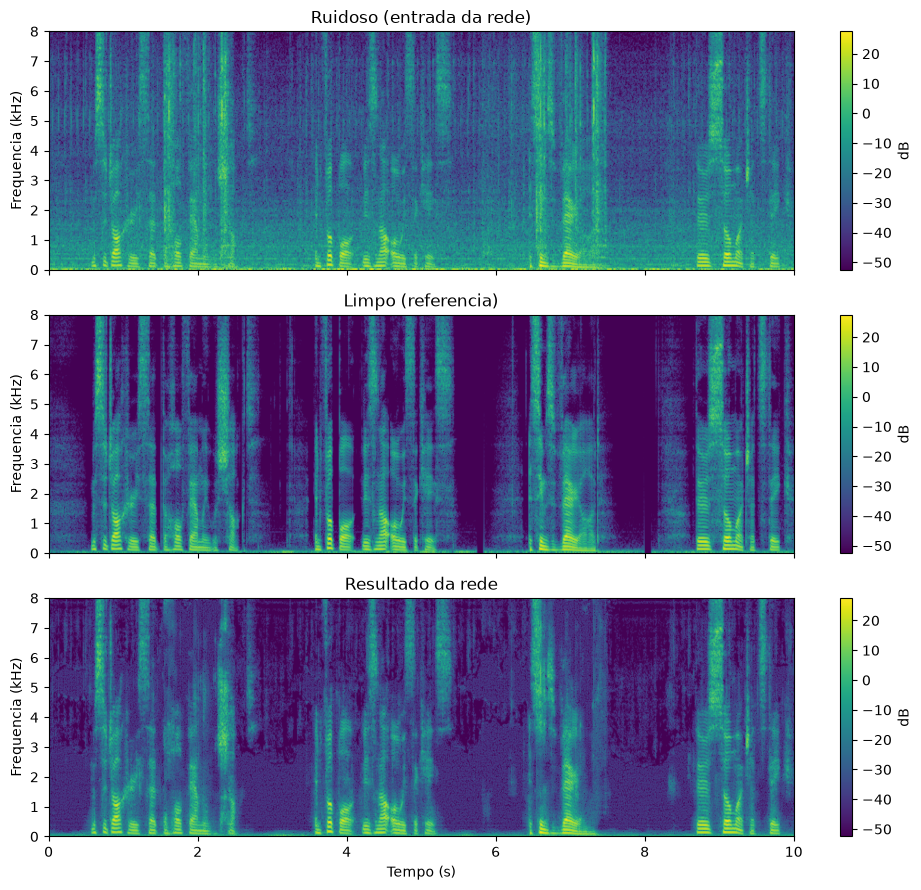

In [7]:
def magnitude_db(audio):
    return 20 * np.log10(np.abs(calcular_stft(audio)) + 1e-8)


db_ruidoso = magnitude_db(ruidoso)
db_limpo = magnitude_db(limpo)
db_estimado = magnitude_db(estimado.astype(np.float32))

# escala comum aos tres paineis
maximo = max(db_ruidoso.max(), db_limpo.max(), db_estimado.max())
minimo = maximo - 80

duracao = menor / TAXA_AMOSTRAGEM
extensao = [0, duracao, 0, TAXA_AMOSTRAGEM / 2 / 1000]   # tempo x kHz

figura, eixos = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

titulos = ["Ruidoso (entrada da rede)", "Limpo (referencia)", "Resultado da rede"]
matrizes = [db_ruidoso, db_limpo, db_estimado]

for i in range(3):
    imagem = eixos[i].imshow(matrizes[i], origin="lower", aspect="auto",
                             cmap="viridis", vmin=minimo, vmax=maximo,
                             extent=extensao)
    eixos[i].set_title(titulos[i])
    eixos[i].set_ylabel("Frequencia (kHz)")
    figura.colorbar(imagem, ax=eixos[i], label="dB")

eixos[2].set_xlabel("Tempo (s)")

figura.tight_layout()
plt.show()

## 7. Ouvir os resultados

In [8]:
print("Ruidoso (entrada):")
display(Audio(ruidoso, rate=TAXA_AMOSTRAGEM))

print("Limpo (referencia):")
display(Audio(limpo, rate=TAXA_AMOSTRAGEM))

print("Resultado da rede:")
display(Audio(estimado, rate=TAXA_AMOSTRAGEM))

Ruidoso (entrada):


Limpo (referencia):


Resultado da rede:


---

Para a avaliação completa (200 arquivos da validação, com a tabela de melhora
de SDR por SNR de entrada), rode:

```
env -u TF_USE_LEGACY_KERAS python simple/3_avaliar_modelo.py
```